# Deep Learning Neural Network Training Practice

In [3]:
import pandas as pd
df  = pd.read_csv(r"C:\Users\Dell\ANN - Deep Learning\dl_training_practice_dataset.csv")
df.head()
df.info()
df.describe()
df.isnull().sum()
print(df.columns)
print(df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   study_hours     200 non-null    float64
 1   attendance      200 non-null    float64
 2   previous_marks  200 non-null    float64
 3   final_marks     200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB
Index(['study_hours', 'attendance', 'previous_marks', 'final_marks'], dtype='str')
(200, 4)


In [5]:
# separating the features and target variable
X = df[["study_hours", "attendance", "previous_marks"]]
y = df["final_marks"]

print("X:")
print(X.head())

print("\ny:")
print(y.head())



X:
   study_hours  attendance  previous_marks
0          8.0        87.8            51.6
1          4.9        98.5            85.5
2          8.7        72.5            78.0
3          7.3        52.9            41.1
4          1.8        45.8            89.8

y:
0    76.5
1    83.3
2    84.8
3    48.6
4    59.3
Name: final_marks, dtype: float64


In [6]:
# train-test split
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("X_test shape:", x_test.shape)
print("y_test shape:", y_test.shape)
print("X_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)

X_test shape: (40, 3)
y_test shape: (40,)
X_train shape: (160, 3)
y_train shape: (160,)


In [7]:
# scalling the features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)
print(x_train[:5])

     study_hours  attendance  previous_marks
79           8.1        91.8            57.6
197          8.9        61.2            69.9
38           3.0        46.0            76.0
24           8.0        60.8            68.3
122          1.8        63.1            43.4


In [10]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model = Sequential([
    Dense(8, activation="relu"),
    Dense(4, activation="relu"),
    Dense(1, activation="linear")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [11]:
# compiling the model
model.compile(
    optimizer="rmsprop",
    loss="mean_squared_error"
)

In [12]:
# actually training the model
history = model.fit(
    x_train,
    y_train,
    epochs=50,
    batch_size=16,
    validation_split=0.2
)


Epoch 1/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 4649.4165 - val_loss: 4331.0967
Epoch 2/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 4647.8848 - val_loss: 4329.8750
Epoch 3/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 4646.6895 - val_loss: 4328.7705
Epoch 4/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 4645.5713 - val_loss: 4327.7085
Epoch 5/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 4644.4829 - val_loss: 4326.6631
Epoch 6/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 4643.4058 - val_loss: 4325.6221
Epoch 7/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 4642.3350 - val_loss: 4324.5850
Epoch 8/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 4641.2632 - val_loss: 4323.5474
Epoch 9/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 4640.1948 - val_loss: 4322.5156
Epoch 10/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 4639.1270 - val_loss: 4321.4780
Epoch 11/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 4638.0605 - val_loss: 4320.4463
Epoch 12/50
8/8 ━━━

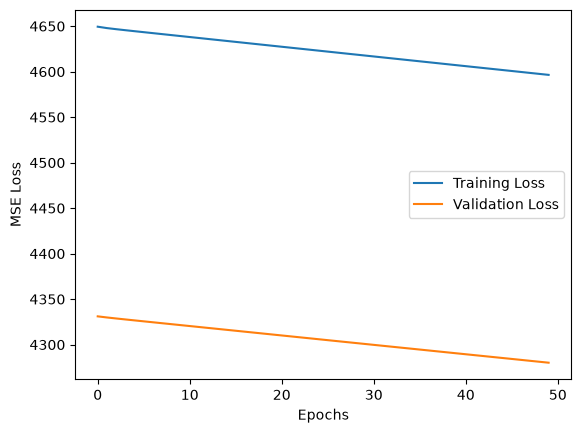

In [13]:
#  complete the training and evaluate the model
import matplotlib.pyplot as plt
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.legend(["Training Loss", "Validation Loss"])
 
plt.show()


In [14]:
# predict in dataset
y_pred = model.predict(x_test)
print("predicted Marks:")
print(y_pred[:10])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
predicted Marks:
[[0.40881118]
 [0.40881118]
 [0.40881118]
 [0.40881118]
 [0.40881118]
 [0.40881118]
 [0.40881118]
 [0.40881118]
 [0.40881118]
 [0.40881118]]


In [15]:
# compare actual and predicted values
results = pd.DataFrame({"Actual": y_test, "Predicted": y_pred.flatten()})
results.head(10)

,Actual,Predicted
95,75.7,0.408811
15,61.9,0.408811
30,80.7,0.408811
158,75.3,0.408811
128,63.5,0.408811
115,67.1,0.408811
69,60.0,0.408811
170,62.8,0.408811
174,62.1,0.408811
45,86.7,0.408811


In [16]:
# calulate model performance metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
mse = mean_squared_error(y_test, y_pred.flatten())
mae = mean_absolute_error(y_test, y_pred.flatten())
rmse = np.sqrt(mse)
print("mse:", mse)
print("mae:", mae)
print("rmse:", rmse)


mse: 4445.259374363271
mae: 65.60118881821631
rmse: 66.67277836091182


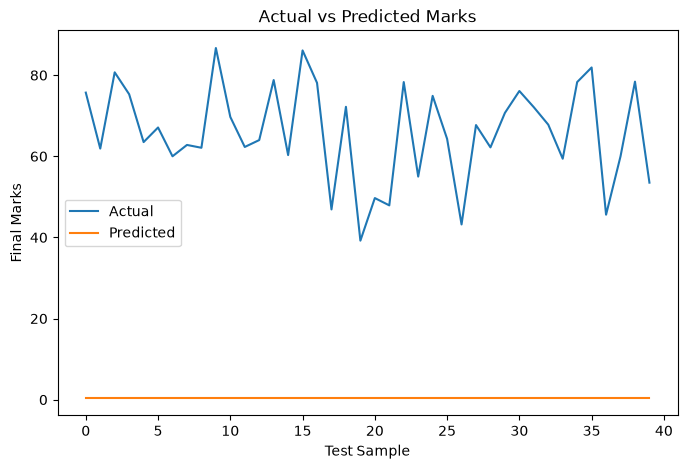

In [18]:
# actual vs predicted graph
plt.figure(figsize=(8, 5))

plt.plot(y_test.values, label="Actual")
plt.plot(y_pred.flatten(), label="Predicted")

plt.xlabel("Test Sample")
plt.ylabel("Final Marks")
plt.title("Actual vs Predicted Marks")
plt.legend()

plt.show()

In [19]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (16, 8)                │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (16, 4)                │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (16, 1)                │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 148 (596.00 B)

 Trainable params: 73 (292.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 75 (304.00 B)

In [20]:
for layer in model.layers:
    print("\nLayer:", layer.name)

    weights, biases = layer.get_weights()

    print("Weights:")
    print(weights)

    print("Biases:")
    print(biases)


Layer: dense
Weights:
[[-0.13099104  0.31540018 -0.6382171   0.41429693 -0.64934736  0.5238556
  -0.10720068 -0.67041016]
 [-0.18565834  0.65927404 -0.04566979 -0.37547773 -0.00345355 -0.36799362
  -0.07484955 -0.41439718]
 [-0.15934229 -0.35414553 -0.6406916  -0.53515863 -0.5269843  -0.14387262
   0.44965178 -0.33860138]]
Biases:
[0. 0. 0. 0. 0. 0. 0. 0.]

Layer: dense_1
Weights:
[[-3.3618113e-01  4.4385940e-01 -3.7855574e-01  2.3229641e-01]
 [-6.2577581e-01 -2.8962624e-01  1.2290180e-02 -5.0307930e-01]
 [ 2.2650361e-02  3.0181545e-01  9.5610976e-02 -4.9842593e-01]
 [ 3.9193636e-01  2.9753804e-02  4.3174332e-01 -7.9103887e-02]
 [ 4.9109334e-01 -4.7992632e-01 -4.1684851e-01 -4.5406318e-01]
 [ 2.7394825e-01  6.4960957e-02 -6.2116700e-01 -1.3661647e-01]
 [-3.7466425e-01 -4.3719515e-01 -4.1504699e-01 -4.7218800e-04]
 [-2.4035436e-01  2.5867426e-01  5.5587524e-01 -1.2757933e-01]]
Biases:
[0. 0. 0. 0.]

Layer: dense_2
Weights:
[[ 0.02211785]
 [ 0.97110605]
 [ 0.33518767]
 [-0.03258359]]
Bi

In [21]:
# final test performance check   
test_loss = model.evaluate(x_test, y_test,verbose=0)
print("Test Loss (MSE):", test_loss)

Test Loss (MSE): 4445.25927734375


In [22]:
# new data for prediction
new_student = [[7.0,85.0, 70.0]]
new_student_scaled = scaler.transform(new_student)

predicted_marks = model.predict(new_student_scaled)
print("Predicted Marks for new student:", predicted_marks[0][0])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
Predicted Marks for new student: 0.40881118


c:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [ ]:
# complete work flow